In [23]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# 1. Instantiate DistilGPT-2's `tokenizer` and `model` using the `.from_pretrained` method.
tokenizer = GPT2Tokenizer.from_pretrained("distilgpt2")
model = GPT2LMHeadModel.from_pretrained("distilgpt2")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

In [24]:
# 2. Assign pt_tensors the input text's tokens in PyTorch tensor form
def encode_text_as_pt_tensor(text):
    pt_tensors = tokenizer.encode(text, return_tensors="pt")
    return pt_tensors

print(encode_text_as_pt_tensor("hello, world!"))

tensor([[31373,    11,   995,     0]])


In [25]:
from transformers import set_seed

# 3. Use set_seed to make the rest of the notebook's output deterministic. Pass it the number 42.
set_seed(42)

In [26]:
prompt = "The chicken laid an egg"
tokens = encode_text_as_pt_tensor(prompt)
# 4. Instruct the model to generate a completion on your choice of prompt using the greedy search method.
# Pass pad_token_id=tokenizer.eos_token_id as the second argument to prevent seeing a warning.
output_tokens = model.generate(tokens, pad_token_id=tokenizer.eos_token_id, max_new_tokens=50) # type: ignore[attr-defined]

In [27]:
# 5. Decode the resulting tokens.
def decode_tokens(tokens):
    text = tokenizer.decode(tokens)
    return text

decode_tokens(output_tokens[0])

'The chicken laid an egg on the ground, and the egg was cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then'

In [28]:
# 6. Adapt the function below to use beam search in its generations. Then call it three times with 2 beam, 6 beams, and 14 beams.
# Pass pad_token_id=tokenizer.eos_token_id to model.generate to prevent seeing a warning.
def generate_with_beam_search(prompt,num_beams):
    tokens = encode_text_as_pt_tensor(prompt)
    output = model.generate(tokens, num_beams=num_beams, pad_token_id=tokenizer.eos_token_id, max_new_tokens=50) # type: ignore[attr-defined]
    completion = decode_tokens(output[0])
    print(completion)
    return completion

prompt = "The chicken laid an egg"

# make multiple calls to the model here
generate_with_beam_search(prompt, num_beams=2)
generate_with_beam_search(prompt, num_beams=6)
generate_with_beam_search(prompt, num_beams=14)

The chicken laid an egg on the ground, and the egg was cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then cooked. The chicken was then
The chicken laid an egg on top of the egg.












































The chicken laid an egg on top of it.















































'The chicken laid an egg on top of it.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'

In [29]:
# 7. Repeat the same process you did with beam search on step 6 with n-gram penalties here.
# Call our function three times with n_gram values of 2, 3, and 4.
# Pass pad_token_id=tokenizer.eos_token_id to model.generate to prevent seeing a warning.
def generate_with_ngram_penalty(prompt, n_gram_penalty, num_beams=6):
    tokens = encode_text_as_pt_tensor(prompt)
    output = model.generate(tokens, num_beams=num_beams, no_repeat_ngram_size=n_gram_penalty, pad_token_id=tokenizer.eos_token_id, max_new_tokens=50) # type: ignore[attr-defined]
    completion = decode_tokens(output[0])
    print(completion)
    return completion

# make multiple calls to the function here
generate_with_ngram_penalty(prompt, 2)
generate_with_ngram_penalty(prompt, 3)
generate_with_ngram_penalty(prompt, 4)

The chicken laid an egg on top of the egg.

The egg was then placed in the oven for about 30 minutes. After that, the chicken was ready to serve.<|endoftext|>
The chicken laid an egg on top of the egg.


The egg was then placed on the bottom of the chicken.
The eggs were then placed in the oven.
When the chicken was ready to eat, the egg was placed in a large bowl.

The chicken laid an egg on top of the egg. The egg was then placed on the top of the chicken.


The chicken was then placed in the oven. The chicken was then put on the bottom of the chicken and placed on top of it.
The


'The chicken laid an egg on top of the egg. The egg was then placed on the top of the chicken.\n\n\nThe chicken was then placed in the oven. The chicken was then put on the bottom of the chicken and placed on top of it.\nThe'

In [30]:
# 8. Same as steps 6 and 7, experiment with different settings of temperature and top_k here after instructing the model to do sampling.
# Choose your own values for temperature and top k and see how the model's output responds.
# Pass pad_token_id=tokenizer.eos_token_id to model.generate to prevent seeing a warning.

def generate_with_sampling(prompt, temperature, top_k, n_gram_penalty=2):
    tokens = encode_text_as_pt_tensor(prompt)
    output = model.generate( # type: ignore[attr-defined]
        tokens, 
        no_repeat_ngram_size=n_gram_penalty, 
        pad_token_id=tokenizer.eos_token_id,
        do_sample=True,
        temperature=temperature,
        top_k=top_k,
        max_new_tokens=50 # type: ignore[attr-defined]
    ) 
    completion = decode_tokens(output[0])
    print(f"Temperature: {temperature}\nTop K: {top_k}\n {completion}")
    return completion

# make multiple calls to the function here
generate_with_sampling(prompt, temperature=0.7, top_k=40)
generate_with_sampling(prompt, temperature=1.0, top_k=80)
generate_with_sampling(prompt, temperature=1.3, top_k=20)

Temperature: 0.7
Top K: 40
 The chicken laid an egg on the top of the chicken in the oven, then wrapped the egg in a wire wrap.

If you like this recipe, you can also check out my blog posts about what made me happy.<|endoftext|>
Temperature: 1.0
Top K: 80
 The chicken laid an egg. You will notice a hole in his stomach, his nose. How can a bone hold a tooth? Is it the bone that is out there? But if it comes down, you will have to dig in. That will give you a sense of
Temperature: 1.3
Top K: 20
 The chicken laid an egg to one of the two eggs and the egg was not fully covered and not even partially covered. (In fact, the eggs still lay in it during a meal because they didn't get to the point where it was a foodie or a friend of


"The chicken laid an egg to one of the two eggs and the egg was not fully covered and not even partially covered. (In fact, the eggs still lay in it during a meal because they didn't get to the point where it was a foodie or a friend of"

In [31]:
from codecarbon import track_emissions

# 9. Add the CodeCarbon decorator to the line directly above this function.
# Then fill the function in with your preferred settings.

@track_emissions
def generate_with_sampling(prompt, temperature, top_k, n_gram_penalty=2):
    tokens = encode_text_as_pt_tensor(prompt)
    output = model.generate( # type: ignore[attr-defined]
        tokens, 
        no_repeat_ngram_size=n_gram_penalty, 
        pad_token_id=tokenizer.eos_token_id,
        do_sample=True,
        temperature=temperature,
        top_k=top_k,
        max_new_tokens=50 # type: ignore[attr-defined]
    ) 
    completion = decode_tokens(output[0])
    print(f"Temperature: {temperature}\nTop K: {top_k}\n {completion}")
    return completion

generate_with_sampling("Carbon dioxide is a", 0.6, 50)

[codecarbon WARNING @ 13:07:32] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 13:07:32] Emissions data (if any) will be saved to file c:\Users\nomadant\AI_Engineering_Lessons\Codecademy\Transformers\emissions.csv
[codecarbon INFO @ 13:07:34] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 13:07:34] >>> Tracker's metadata:
[codecarbon INFO @ 13:07:34]   Platform system: Windows-11-10.0.26300-SP0
[codecarbon INFO @ 13:07:34]   Python version: 3.14.6
[codecarbon INFO @ 13:07:34]   CodeCarbon version: 3.3.1
[codecarbon INFO @ 13:07:34]   Available RAM : 15.768 GB
[codecarbon INFO @ 13:07:34]   CPU count: 12 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 13:07:34]   CPU model: Intel(R) Core(TM) i7-10750H CPU @ 2.60GHz
[codecarbon INFO @ 13:07:34]   GPU count: 1
[codecarbon INFO @ 13:07:34]   GPU model: 1 x NVIDIA GeForce RTX 2070 Super
[codecarbon INFO @ 13:07:34] Energy consumed for RAM : 0.000000 kWh. RAM Power : 10.0 

Temperature: 0.6
Top K: 50
 Carbon dioxide is a potent greenhouse gas that contributes to climate change. The greenhouse gases released by the release of methane, which is released through the atmosphere, are released to the Earth's atmosphere.

The release is an important climate-change event, because it is the


[codecarbon INFO @ 13:07:38] Done!



"Carbon dioxide is a potent greenhouse gas that contributes to climate change. The greenhouse gases released by the release of methane, which is released through the atmosphere, are released to the Earth's atmosphere.\n\nThe release is an important climate-change event, because it is the"

In [32]:
import pandas as pd
# 10. Use pandas' read_csv method to load in the emissions.csv we generated.
# Then, print the first few rows with emissions.head().

emissions = pd.read_csv('emissions.csv')
print(emissions.head())

             timestamp project_name                                run_id  \
0  2026-10-19T13:04:14   codecarbon  c026c4f3-e9bf-405d-aab4-b1143624e0c8   
1  2026-10-19T13:06:21   codecarbon  552596b3-d5c7-412d-9b03-f6932fec12e8   
2  2026-10-19T13:07:38   codecarbon  19ebd302-3d5c-4ecd-81d9-bbf0c67cd13a   

                          experiment_id  duration  emissions  emissions_rate  \
0  5b0fa12a-3dd7-45bb-9766-cc326314d9f1  3.742618   0.000001    3.114818e-07   
1  5b0fa12a-3dd7-45bb-9766-cc326314d9f1  3.878061   0.000001    3.721449e-07   
2  5b0fa12a-3dd7-45bb-9766-cc326314d9f1  4.240932   0.000003    6.637530e-07   

    cpu_power  gpu_power  ram_power  ...  latitude  ram_total_size  \
0   80.450281  22.373014       10.0  ...   47.5731       15.767586   
1   83.610663  18.388160       10.0  ...   47.5731       15.767586   
2  116.342928  20.789721       10.0  ...   47.5731       15.767586   

   tracking_mode  cpu_utilization_percent  gpu_utilization_percent  \
0        machine   

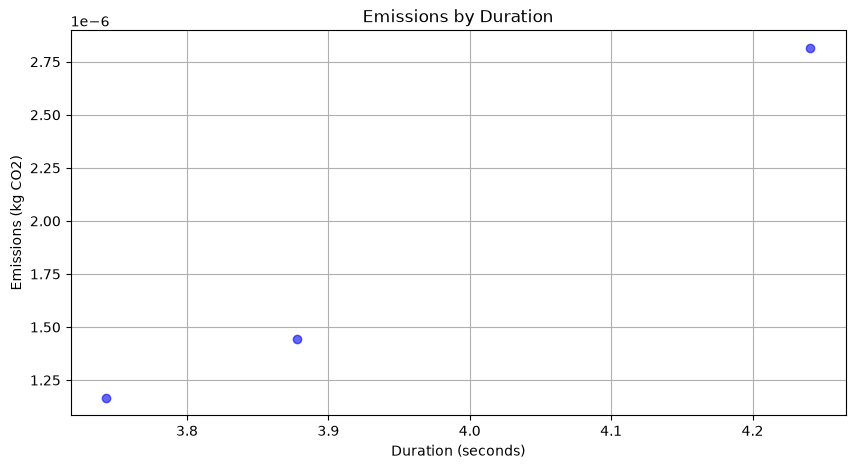

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
# 11. Pass the `emissions` DataFrame's 'duration' column to the x-axis (first argument) and the 'emissions' column to the y-axis (second argument).
plt.scatter(emissions['duration'], emissions['emissions'], color='blue', alpha=0.6) # pass the columns here, then include `color='blue', alpha=0.6)`
plt.title('Emissions by Duration')
plt.xlabel('Duration (seconds)')
plt.ylabel('Emissions (kg CO2)')
plt.grid(True)
plt.show()